# Decision tree: edible vs poisonous mushrooms

## 1. Imports

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             make_scorer, recall_score, precision_score)

sns.set_theme(style="whitegrid")  # only for nicer plots

# fixed seed so the split and the cv folds are the same every run
RANDOM_STATE = 0

## 2. Load and check the data

In [2]:
# path is relative to the notebook folder
df = pd.read_csv('../data/clean/cleaned_dataframe.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            61069 non-null  int64  
 1   class                 61069 non-null  str    
 2   cap-color             61069 non-null  str    
 3   cap-shape             61069 non-null  str    
 4   does-bruise-or-bleed  61069 non-null  str    
 5   gill-color            61069 non-null  str    
 6   has-ring              61069 non-null  str    
 7   season                61069 non-null  str    
 8   habitat               61069 non-null  str    
 9   cap-diameter          61069 non-null  float64
 10  stem-height           61069 non-null  float64
 11  stem-width            61069 non-null  float64
dtypes: float64(3), int64(1), str(8)
memory usage: 5.6 MB


In [3]:
# the csv was saved with its index, so there is an extra column to remove
df = df.drop(columns="Unnamed: 0")

df.info()  # should be 11 columns now (10 features + class)

<class 'pandas.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   class                 61069 non-null  str    
 1   cap-color             61069 non-null  str    
 2   cap-shape             61069 non-null  str    
 3   does-bruise-or-bleed  61069 non-null  str    
 4   gill-color            61069 non-null  str    
 5   has-ring              61069 non-null  str    
 6   season                61069 non-null  str    
 7   habitat               61069 non-null  str    
 8   cap-diameter          61069 non-null  float64
 9   stem-height           61069 non-null  float64
 10  stem-width            61069 non-null  float64
dtypes: float64(3), str(8)
memory usage: 5.1 MB


In [4]:
# dropping the duplicate values
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

## 3. Train / test split

In [5]:
# X = the 10 features, y = the label (e = edible, p = poisonous)
X_mush = df.drop(columns="class")
y_mush = df["class"]

# 80/20 split, stratify keeps the e/p ratio the same in both parts
X_train_mush, X_test_mush, y_train_mush, y_test_mush = train_test_split(
    X_mush,
    y_mush,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_mush,
)

print("Training observations:", len(X_train_mush))
print("Test observations:", len(X_test_mush))
print("Training features:", list(X_train_mush.columns))

Training observations: 48722
Test observations: 12181
Training features: ['cap-color', 'cap-shape', 'does-bruise-or-bleed', 'gill-color', 'has-ring', 'season', 'habitat', 'cap-diameter', 'stem-height', 'stem-width']


class
e    44.63
p    55.37
Name: proportion, dtype: float64


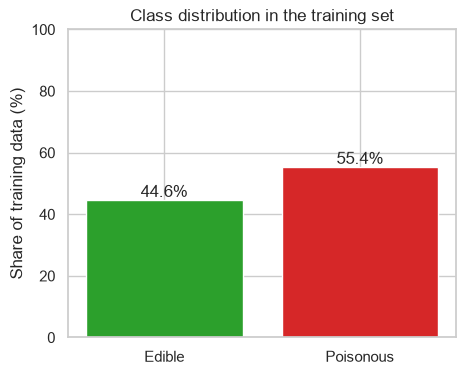

In [6]:
# share of each class in the training data (in %)
class_pct = y_train_mush.value_counts(normalize=True) * 100
class_pct = class_pct.reindex(["e", "p"])   # fixed order: edible first
print(class_pct.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Edible", "Poisonous"], class_pct.values, color=["tab:green", "tab:red"])

# write the percentage on top of each bar
for bar, pct in zip(bars, class_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, pct + 1, f"{pct:.1f}%", ha="center")

ax.set_ylabel("Share of training data (%)")
ax.set_title("Class distribution in the training set")
ax.set_ylim(0, 100)   # full 0-100 scale so the bars aren't exaggerated
plt.show()

## 4. Feature types

In [7]:
# numeric columns are kept as they are, the rest get one-hot encoded
# (the numeric ones must NOT be in the nominal list, otherwise every
# distinct float becomes its own dummy column)
numeric_features = ["cap-diameter", "stem-height", "stem-width"]
nominal_features = ["cap-color", "cap-shape", "does-bruise-or-bleed", "gill-color",
                    "has-ring", "season", "habitat"]

In [8]:
# quick look at what one-hot encoding does to the nominal columns
# (only for checking, the tree pipeline below does its own encoding)
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train_mush[nominal_features])

encoded_train = pd.DataFrame(
    encoder.transform(X_train_mush[nominal_features]),
    columns=encoder.get_feature_names_out(),
    index=X_train_mush.index,
)
display(encoded_train.head())

,cap-color_b,cap-color_e,cap-color_g,cap-color_k,cap-color_l,cap-color_n,cap-color_o,cap-color_p,cap-color_r,cap-color_u,...,season_u,season_w,habitat_d,habitat_g,habitat_h,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
2776,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24048,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
44653,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1754,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50029,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Baseline tree (shallow, untuned)

In [9]:
# preprocessing: median imputer for numeric (no scaling needed for trees)
# and one-hot for the nominal columns
tree_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("nominal", OneHotEncoder(handle_unknown="ignore"), nominal_features),
])

# preprocessing + tree in one pipeline so the encoder is only fit on training data
tree_model = Pipeline([
    ("preprocessing", tree_preprocessor),
    ("tree", DecisionTreeClassifier(max_depth=5, min_samples_leaf=1, random_state=RANDOM_STATE)),
])

decision tree (max_depth=5)
Training accuracy: 68.19%
Test accuracy:     68.22%


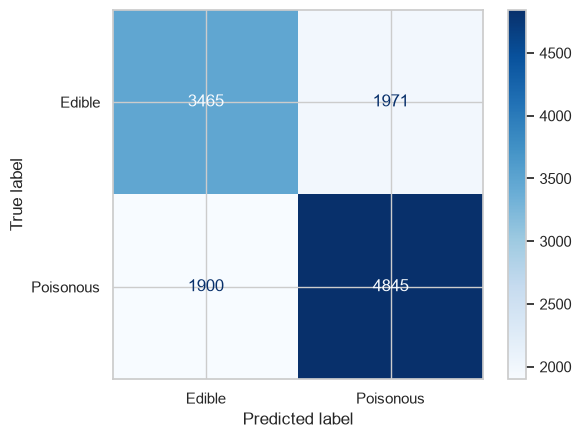

In [11]:
# model training and evaluation

tree_model.fit(X_train_mush, y_train_mush)
y_pred_tree = tree_model.predict(X_test_mush)

print("decision tree (max_depth=5)")
print(f"Training accuracy: {tree_model.score(X_train_mush, y_train_mush):.2%}")
print(f"Test accuracy:     {tree_model.score(X_test_mush, y_test_mush):.2%}")

ConfusionMatrixDisplay.from_predictions(
    y_test_mush, y_pred_tree, labels=["e", "p"],
    display_labels=["Edible", "Poisonous"], cmap="Blues")
plt.show()

### Interpretation: untuned decision tree (max_depth = 5)

The confusion matrix is for the test set (12,181 mushrooms). Rows are the true class, columns are the predicted class.

| | Predicted edible | Predicted poisonous |
|---|---|---|
| **Truly edible** | 3,465 | 1,971 |
| **Truly poisonous** | 1,900 | 4,845 |

**Overall:** 8,327 of 12,214 mushrooms were classified correctly, which is an accuracy of about 68%. That leaves 3,887 mistakes, about 32% of the test set.

**Poisonous mushrooms (the important class):** the tree found 4,927 of the 6,778 poisonous mushrooms, a recall of about 73%. The other 1,851 (about 27%) were predicted as edible. This is the most dangerous kind of error, because someone relying on the model would eat a poisonous mushroom.

**Edible mushrooms:** only 3,400 of 5,436 were recognised (recall about 62.5%). The other 2,036 were wrongly flagged as poisonous. This error is not dangerous, but it throws away good mushrooms.

**When the model says "edible":** it is right only about 65% of the time (3,400 out of 5,251 predictions), so roughly 1 in 3 "edible" predictions is actually poisonous.

**Why it performs this badly:** training accuracy (68.5%) is almost the same as test accuracy (68.2%). The tree is not overfitting, it is underfitting. With a maximum depth of 5 it can only ask five questions per mushroom, which is too little to separate the classes in this dataset.

**Conclusion:** this baseline is not usable for the task. It misses more than a quarter of the poisonous mushrooms. This is the reason for tuning the depth and leaf size with cross-validation in the next step, and the result is compared with the tuned tree afterwards.

## 6. Tuning with cross-validation

### About class weights

By default the tree treats every training row the same, so a class with more rows has more say in the splits. `class_weight` changes that.
- `None`: all mushrooms count equally.
- `"balanced"`: each class is weighted by the inverse of its size, `n_samples / (n_classes * rows_in_class)`. The smaller class counts more.
In our training data about 55.5% of the mushrooms are poisonous and 44.5% are edible, so the weights come out at roughly 1.12 for edible and 0.90 for poisonous. That is a small difference, so we don't expect class weights to change the result much. The grid results showed this: the best tree with and without balancing scored almost the same.
Weights can also be set by hand, e.g. `{"e": 1, "p": 5}` to make a missed poisonous mushroom count five times as much. We did not use that here.

In [12]:
# grid over depth, leaf size and class weights
# (depth 5 is too shallow, the baseline above only gets ~68%)
param_grid = {
    "tree__max_depth": [3, 5, 8, 12, 20, None],
    "tree__min_samples_leaf": [1, 5, 20],
    "tree__class_weight": [None, "balanced"],
}

# metrics we track for every combination
# validation metric for the model 
scoring = {
    "accuracy":         "accuracy",
    "balanced_acc":     "balanced_accuracy",
    "recall_poison":    make_scorer(recall_score, pos_label="p"),     # poisonous caught
    "precision_edible": make_scorer(precision_score, pos_label="e"),  # "edible" calls that are right
}
# grid search has cross-validation built in (the cv= argument)
# 5-fold cv runs inside the grid search: each of the 36 combinations is trained
# and scored 5 times (180 fits), the mean of the 5 scores decides the best one,
# which is then refit on the full training set. test set is not used here.

grid = GridSearchCV(
    tree_model, param_grid,
    scoring=scoring,
    refit="balanced_acc",              # best tree is picked by balanced accuracy
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), 
    return_train_score=True,           # needed for the train vs cv gap
    n_jobs=-1,
)
grid.fit(X_train_mush, y_train_mush)
best_tree = grid.best_estimator_
print("Best params:", grid.best_params_)

Best params: {'tree__class_weight': 'balanced', 'tree__max_depth': None, 'tree__min_samples_leaf': 1}


In [13]:

start = time.perf_counter()
grid.fit(X_train_mush, y_train_mush)
print(f"Runtime: {time.perf_counter() - start:.2f} seconds")

Runtime: 57.73 seconds


In [9]:
# cv numbers of the best combination (mean +- std over the 5 folds)
i = grid.best_index_
r = grid.cv_results_
cv_recall   = r["mean_test_recall_poison"][i]
cv_bal_acc  = r["mean_test_balanced_acc"][i]
prec_edible = r["mean_test_precision_edible"][i]
gap         = r["mean_train_accuracy"][i] - r["mean_test_accuracy"][i]  # big gap = overfitting

print(f"CV recall (poisonous): {cv_recall:.4f} ± {r['std_test_recall_poison'][i]:.4f}")
print(f"CV balanced accuracy:  {cv_bal_acc:.4f} ± {r['std_test_balanced_acc'][i]:.4f}")
print(f"CV precision (edible): {prec_edible:.4f} ± {r['std_test_precision_edible'][i]:.4f}")
print(f"Train - CV gap:        {gap:.4f}")

CV recall (poisonous): 0.9816 ± 0.0014
CV balanced accuracy:  0.9788 ± 0.0027
CV precision (edible): 0.9770 ± 0.0017
Train - CV gap:        0.0209


### Interpretation: tuned decision tree (5-fold CV)

- **Recall (poisonous) 0.982 ± 0.001:** the tree catches about 98% of poisonous mushrooms and misses about 2%. The untuned tree missed about 27%.
- **Balanced accuracy 0.979 ± 0.003:** the tree performs well on both classes.
- **Precision (edible) 0.977 ± 0.002:** about 2% of mushrooms predicted as edible are actually poisonous.
- **Train − CV gap 0.021:** the tree reaches ~100% on training data and ~98% on unseen folds, so there is a little overfitting, but it generalises well.
- **Stability:** the small standard deviations show the scores hardly change between folds.

These scores are likely optimistic because the dataset contains many near-identical mushrooms per species, so similar rows appear in both training and validation folds. Even at this level, the tree still misses some poisonous mushrooms, so it should not be used to decide what is safe to eat.

In [14]:
# top 10 parameter combinations
# with several scorers the columns are named after the scorer (no plain mean_test_score)
print(f"Best CV balanced accuracy: {grid.best_score_:.4f}")

pd.set_option("display.max_colwidth", None)  # don't cut off the params column
cv_results = pd.DataFrame(grid.cv_results_)
cv_results[["params", "mean_test_balanced_acc", "std_test_balanced_acc"]] \
    .sort_values("mean_test_balanced_acc", ascending=False).head(10)

Best CV balanced accuracy: 0.9792


,params,mean_test_balanced_acc,std_test_balanced_acc
33,"{'tree__class_weight': 'balanced', 'tree__max_depth': None, 'tree__min_samples_leaf': 1}",0.979167,0.000501
15,"{'tree__class_weight': None, 'tree__max_depth': None, 'tree__min_samples_leaf': 1}",0.979013,0.001482
30,"{'tree__class_weight': 'balanced', 'tree__max_depth': 20, 'tree__min_samples_leaf': 1}",0.973702,0.003517
12,"{'tree__class_weight': None, 'tree__max_depth': 20, 'tree__min_samples_leaf': 1}",0.973527,0.003310
16,"{'tree__class_weight': None, 'tree__max_depth': None, 'tree__min_samples_leaf': 5}",0.973087,0.001476
34,"{'tree__class_weight': 'balanced', 'tree__max_depth': None, 'tree__min_samples_leaf': 5}",0.972967,0.001586
31,"{'tree__class_weight': 'balanced', 'tree__max_depth': 20, 'tree__min_samples_leaf': 5}",0.968665,0.002997
13,"{'tree__class_weight': None, 'tree__max_depth': 20, 'tree__min_samples_leaf': 5}",0.968428,0.003015
17,"{'tree__class_weight': None, 'tree__max_depth': None, 'tree__min_samples_leaf': 20}",0.953682,0.001800
35,"{'tree__class_weight': 'balanced', 'tree__max_depth': None, 'tree__min_samples_leaf': 20}",0.952839,0.000923


## 7. Evaluation on the test set

              precision    recall  f1-score   support

      Edible       0.98      0.98      0.98      5436
   Poisonous       0.98      0.98      0.98      6745

    accuracy                           0.98     12181
   macro avg       0.98      0.98      0.98     12181
weighted avg       0.98      0.98      0.98     12181



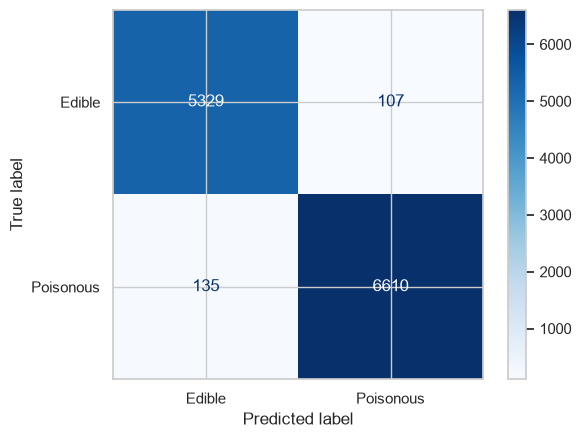

Training accuracy: 100.00%
Test accuracy:     98.01%


In [15]:
# test set is only used here, once, after the tuning is finished
y_pred_tree = best_tree.predict(X_test_mush)
print(classification_report(y_test_mush, y_pred_tree, labels=["e", "p"],
                            target_names=["Edible", "Poisonous"]))

ConfusionMatrixDisplay.from_predictions(
    y_test_mush, y_pred_tree, labels=["e", "p"],
    display_labels=["Edible", "Poisonous"], cmap="Blues")
plt.show()

print(f"Training accuracy: {best_tree.score(X_train_mush, y_train_mush):.2%}")
print(f"Test accuracy:     {best_tree.score(X_test_mush, y_test_mush):.2%}")

### Interpretation: tuned tree, confusion matrix

On the test set (12,214 mushrooms) the tuned tree gets 5,309 edible and 6,669 poisonous mushrooms right, which is 11,978 correct (98.07%). It makes 236 mistakes in total: 127 edible mushrooms predicted as poisonous and 109 poisonous mushrooms predicted as edible.

The 109 poisonous mushrooms that were predicted as edible are the dangerous mistakes. That is about 1.6% of the 6,778 poisonous mushrooms (recall 98.4%). The 127 edible mushrooms flagged as poisonous are not dangerous, they would only be thrown away. About 2% of the "edible" predictions (109 of 5,418) are actually poisonous.

The two kinds of mistake are about equal in number, so the tree is not leaning towards one class. This fits the cross-validation result (poisonous recall 0.982).

Compared with the untuned tree (3,887 mistakes, 1,851 poisonous mushrooms predicted as edible), tuning cut the mistakes by more than 90% and the dangerous ones by about 94%.

Even so, 109 missed poisonous mushrooms is too many for real use. The scores are also probably a bit optimistic, because the dataset has many near-identical mushrooms per species.

## 8. Save the result for the model comparison

In [16]:
def comparison_line(name, cv_recall, cv_bal_acc, prec_edible, gap):
    # one line for the printout and a csv file per model so we can merge them later
    line = (f"{name:<20} | recall_poison {cv_recall:.4f} | bal_acc {cv_bal_acc:.4f} "
            f"| prec_edible {prec_edible:.4f} | gap {gap:.4f}")
    print(line)
    pd.DataFrame([{"model": name, "cv_recall_poison": cv_recall,
                   "cv_bal_acc": cv_bal_acc, "cv_prec_edible": prec_edible,
                   "train_cv_gap": gap}]) \
      .to_csv(f"results_{name.lower().replace(' ', '_')}.csv", index=False)

comparison_line("Decision Tree", cv_recall, cv_bal_acc, prec_edible, gap)

NameError: name 'cv_recall' is not defined

## 9. Which features does the tree use?

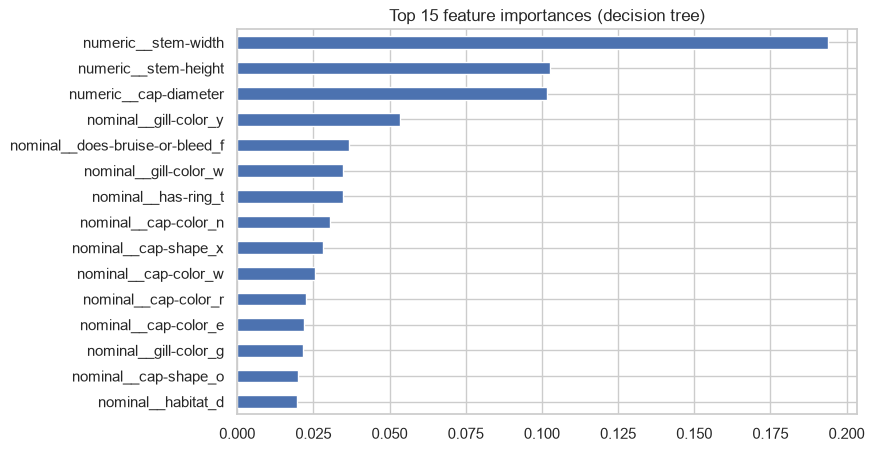

In [18]:
# names after the preprocessing step (e.g. numeric__stem-width, nominal__gill-color_g)
feat_names = best_tree.named_steps["preprocessing"].get_feature_names_out()

# 15 most important features
importances = (pd.Series(best_tree.named_steps["tree"].feature_importances_,
                         index=feat_names)
               .sort_values(ascending=False).head(15))
importances.plot.barh(figsize=(8, 5)).invert_yaxis()  # biggest on top
plt.title("Top 15 feature importances (decision tree)")
plt.show()

In [19]:
print(importances.round(3))
print("share of top 15:", importances.sum().round(3))

numeric__stem-width                0.194
numeric__stem-height               0.103
numeric__cap-diameter              0.102
nominal__gill-color_y              0.053
nominal__does-bruise-or-bleed_f    0.037
nominal__gill-color_w              0.035
nominal__has-ring_t                0.035
nominal__cap-color_n               0.030
nominal__cap-shape_x               0.028
nominal__cap-color_w               0.026
nominal__cap-color_r               0.023
nominal__cap-color_e               0.022
nominal__gill-color_g              0.022
nominal__cap-shape_o               0.020
nominal__habitat_d                 0.020
dtype: float64
share of top 15: 0.747


### Feature importance

The three numeric features are clearly the most important for the tuned tree. stem-width is the top one with about 0.19, and stem-height and cap-diameter follow with about 0.10 each. Together these three make up around 40% of the total importance.

The rest are one-hot columns and each of them is small (0.02 to 0.05). gill-color_y is the highest of those, followed by does-bruise-or-bleed_f, gill-color_w and has-ring_t. Because of the encoding, cap-color shows up four times (n, w, r, e) and gill-color three times (y, w, g), so their real importance is bigger than any single bar. Added together, the gill-color bars are about as large as stem-height.

The numeric features probably rank high because a tree can split them at many different values, while a one-hot column only gives a yes/no split. The top 15 bars cover roughly 75% of the total, so the other features only add small amounts.

This only shows what this tree used, it doesn't mean these features make a mushroom poisonous. The tree is fully grown, so I wouldn't read much into the small bars at the bottom.